In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
# Permite importar `proyecto` sin instalarlo: el código vive en src/
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

# 04 · Variables — cada idea es una hipótesis que se mide

Crear variables es fácil; saber si **sirven** es lo difícil. Cada idea se mide con **el mismo modelo, los mismos
pliegues y la misma métrica**; solo cambia el conjunto de variables. Una idea entra solo si la mejora supera el
**ruido entre pliegues**.

El código está en `src/proyecto/features/engineering.py` (variables y preprocesamiento) y
`src/proyecto/models/train.py` (pipeline, métricas y validación). Este notebook solo **orquesta**.
Resultado: `reports/04_features.md` y `reports/04_features_tabla.csv`.

## 0. Cargar los datos de entrenamiento

Solo `train.parquet`. **La prueba sigue cerrada** hasta la etapa 7.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier

from proyecto.config import GROUP_COL, PROCESSED_DIR, PROSPER_RATING_START, RANDOM_STATE, REPORTS_DIR, TARGET
from proyecto.data.split import group_cv
from proyecto.features.engineering import add_features, feature_columns
from proyecto.models.train import build_pipeline, feature_frame, fold_metrics, improvement_over_noise, out_of_fold_proba

ID_COL = GROUP_COL   # MemberKey: el prestatario
train = pd.read_parquet(PROCESSED_DIR / "train.parquet")
print(f"entrenamiento: {len(train):,} préstamos, {train[ID_COL].nunique():,} prestatarios, "
      f"{train[TARGET].mean():.2%} de impago  (la prueba NO se abre)")

entrenamiento: 39,641 préstamos, 32,341 prestatarios, 31.04% de impago  (la prueba NO se abre)


## 1. Las ideas, antes de medirlas

**Referencia (fila 0):** perfil de buró del prestatario (puntaje, líneas de crédito, consultas, morosidad,
utilización, deuda/ingreso, ingreso, empleo, vivienda) y condiciones del préstamo que pide (monto, plazo, cuota,
propósito). Son 26 numéricas y 6 categóricas, todas conocidas al publicar la solicitud.

**Fuera del modelo (por diseño, sin medir):** `Investors`, `PercentFunded` e `InvestmentFromFriends*` (resultado de la
financiación, se conocen después de publicar la solicitud), `MemberKey` (solo para partir), `BorrowerState` (su
efecto se prueba solo a través del índice climático), `BorrowerRate` y `LenderYield` (correlación 0,99 con
`BorrowerAPR`) y `CreditScoreRangeUpper` (= `Lower` + 19).

| # | Idea | Variables | Por qué podría ayudar | ¿Se conoce al predecir? |
|---|---|---|---|---|
| 1 | **Índice climático** | `Precipitation_Risk_Index` | Es la hipótesis del caso: el riesgo de inundación del estado agregaría información | Sí (supuesto académico, fijo por estado) |
| 2 | **Puntaje y precio de Prosper** | `BorrowerAPR`, `ProsperRating`, `ProsperScore`, `EstimatedLoss`, `EstimatedReturn`, `EstimatedEffectiveYield`, `CreditGrade` | Prosper ya resume el riesgo con información que quizá no tenemos | Sí, se asignan al publicar la solicitud |
| 3 | **Historial en Prosper** | préstamos previos, pagos a tiempo y atrasados, monto prestado y pendiente, cambio de puntaje, `has_prior_prosper_loan` | En el EDA, los prestatarios con préstamos previos caen menos en impago (18,1 % vs 37,3 %) | Sí, es el historial al publicar |
| 4 | **Razones financieras** | cuota / ingreso mensual, monto / ingreso anual, años de historial crediticio | La misma cuota pesa distinto según el ingreso; a un árbol le cuesta reconstruir un cociente | Sí |
| 5 | **Año de originación** (control) | `origination_year` | La tasa de impago cambia mucho por año (de 52 % en 2006 a 13 % en 2013) | Sí, pero el efecto viene de **cómo se armó la muestra** (solo préstamos terminados) |

**Regla de decisión (escrita ANTES de medir):** se conserva una idea solo si (a) su **mejora / ruido en AUC-PR es
mayor que 1** frente a la referencia, (b) se conoce al momento de predecir y (c) no es un artefacto de cómo se
construyó la muestra. Por (c), la idea 5 se mide solo para saber cuánto pesa la época; **no entra** aunque mejore.

La hipótesis climática se prueba dos veces: contra la referencia y contra el conjunto final (*¿agrega información
más allá del perfil financiero?*).

## 2. Validación común

Los pliegues se calculan **una vez**, por prestatario, y se reutilizan en todas las comparaciones.

In [3]:
X, y = feature_frame(train), train[TARGET].to_numpy()
folds = list(group_cv(n_splits=5, seed=RANDOM_STATE).split(X, y, groups=X[ID_COL]))
for train_idx, valid_idx in folds:   # ningún prestatario en los dos lados de un pliegue
    assert set(X.iloc[train_idx][ID_COL]).isdisjoint(set(X.iloc[valid_idx][ID_COL])), "hay prestatarios en los dos lados"
print(f"{len(folds)} pliegues por {ID_COL}; tamaño de validación: {[len(v) for _, v in folds]}")
print("% impago por pliegue:", [round(y[v].mean(), 4) for _, v in folds])

5 pliegues por MemberKey; tamaño de validación: [7931, 7927, 7927, 7929, 7927]
% impago por pliegue: [np.float64(0.3104), np.float64(0.3103), np.float64(0.3103), np.float64(0.3105), np.float64(0.3103)]


## 3. Qué hacen las variables nuevas

Antes de medir, una mirada simple: ¿separan los impagos? **Ver diferencia no es lo mismo que mejorar el modelo**: un
árbol puede estar reconstruyendo esa información con otras columnas.

In [4]:
sample = add_features(train)
profile = sample.groupby(TARGET)[["payment_to_income", "amount_to_annual_income", "credit_history_years",
                                  "Precipitation_Risk_Index", "BorrowerAPR"]].median()
profile.index = ["pagó", "impago"]
display(profile.round(3))
pd.DataFrame({"% impago": sample.groupby("has_prior_prosper_loan")[TARGET].mean(),
              "préstamos": sample.groupby("has_prior_prosper_loan").size()},
             ).rename(index={0.0: "sin préstamo previo", 1.0: "con préstamo previo"}).round(3)

,payment_to_income,amount_to_annual_income,credit_history_years,Precipitation_Risk_Index,BorrowerAPR
pagó,0.040,0.089,14.018,50.0,0.199
impago,0.047,0.101,13.528,50.0,0.258


,% impago,préstamos
has_prior_prosper_loan,,
sin préstamo previo,0.331,31206
con préstamo previo,0.233,8435


## 4. El experimento

Mismo modelo (**LightGBM con parámetros fijos**, los de partida del ejemplo del curso), mismos 5 pliegues por
prestatario, y solo cambia el conjunto de variables. Para cada variante se guardan las **predicciones fuera de
pliegue** (cada préstamo lo predice el modelo que no lo vio), y de ahí salen las métricas por pliegue.

- **Métrica principal:** AUC-PR de la clase impago.
- **Control:** log loss y Brier (calidad de las probabilidades), ROC-AUC y costo esperado con la matriz 4 a 1.

In [5]:
def fixed_model():
    return LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31,
                          random_state=RANDOM_STATE, verbose=-1, n_jobs=2)

def run(flags):
    return out_of_fold_proba(build_pipeline(fixed_model(), scale=False, **flags), X, y, folds)

variants = {
    "0 · referencia":                    dict(),
    "1 · + índice climático":            dict(use_climate=True),
    "2 · + puntaje y precio de Prosper": dict(use_prosper_scores=True),
    "3 · + historial en Prosper":        dict(use_prosper_history=True),
    "4 · + razones financieras":         dict(use_ratios=True),
    "5 · + año (control)":               dict(use_year=True),
}
oof = {}
for name, flags in variants.items():
    oof[name] = run(flags)
    pr = fold_metrics(y, oof[name], folds)["pr_auc"]
    print(f"{name:36s} AUC-PR = {pr.mean():.4f} ± {pr.std():.4f}")

0 · referencia                       AUC-PR = 0.6005 ± 0.0120


1 · + índice climático               AUC-PR = 0.6007 ± 0.0119


2 · + puntaje y precio de Prosper    AUC-PR = 0.6067 ± 0.0121


3 · + historial en Prosper           AUC-PR = 0.6080 ± 0.0118


4 · + razones financieras            AUC-PR = 0.6021 ± 0.0127


5 · + año (control)                  AUC-PR = 0.6053 ± 0.0144


## 5. Mejora sobre ruido

- `mejora / ruido` = (AUC-PR de la variante − AUC-PR de la referencia) / desviación de la variante entre pliegues.
  Es la regla del curso; menor que ~1 está dentro del ruido.
- `pliegues ganados`: en cuántos de los 5 pliegues la variante supera a la referencia.
- `mejora / ruido de a pares`: la misma mejora dividida por la desviación de la **diferencia** entre pliegues
  (diagnóstico; se explica en la sección 6).

In [6]:
def comparison_table(oof, reference, mask=None):
    per_fold = {name: fold_metrics(y, p, folds, mask=mask) for name, p in oof.items()}
    rows = {}
    for name, table in per_fold.items():
        pr = improvement_over_noise(per_fold[reference]["pr_auc"], table["pr_auc"])
        ll = improvement_over_noise(per_fold[reference]["log_loss"], table["log_loss"], higher_is_better=False)
        rows[name] = {
            "AUC-PR": table["pr_auc"].mean(), "± entre pliegues": table["pr_auc"].std(),
            "mejora AUC-PR": pr["mejora"], "mejora / ruido": pr["mejora / ruido"],
            "pliegues ganados": pr["pliegues ganados"], "mejora / ruido de a pares": pr["mejora / ruido de a pares"],
            "log loss": table["log_loss"].mean(), "mejora log loss / ruido": ll["mejora / ruido"],
            "Brier": table["brier"].mean(), "ROC-AUC": table["roc_auc"].mean(),
            "costo 4 a 1": table["cost"].mean(), "recall impago": table["recall_default"].mean(),
        }
    out = pd.DataFrame(rows).T
    out.loc[reference, "pliegues ganados"] = np.nan
    return out

REF = "0 · referencia"
ideas_table = comparison_table(oof, REF)
ideas_table.round(4)

,AUC-PR,± entre pliegues,mejora AUC-PR,mejora / ruido,pliegues ganados,mejora / ruido de a pares,log loss,mejora log loss / ruido,Brier,ROC-AUC,costo 4 a 1,recall impago
0 · referencia,0.6005,0.0120,0.0000,0.0000,NaN,0.0000,0.5168,0.0000,0.1728,0.7658,0.5312,0.8692
1 · + índice climático,0.6007,0.0119,0.0001,0.0100,3.0,0.0503,0.5165,0.0644,0.1728,0.7661,0.5262,0.8732
2 · + puntaje y precio de Prosper,0.6067,0.0121,0.0061,0.5087,5.0,2.8210,0.5131,1.1107,0.1713,0.7714,0.5184,0.8708
3 · + historial en Prosper,0.6080,0.0118,0.0074,0.6311,5.0,4.4667,0.5116,1.2965,0.1708,0.7725,0.5186,0.8750
4 · + razones financieras,0.6021,0.0127,0.0016,0.1243,4.0,0.7134,0.5160,0.1791,0.1725,0.7669,0.5270,0.8719
5 · + año (control),0.6053,0.0144,0.0048,0.3311,5.0,1.2320,0.5128,0.7347,0.1714,0.7713,0.5163,0.8723


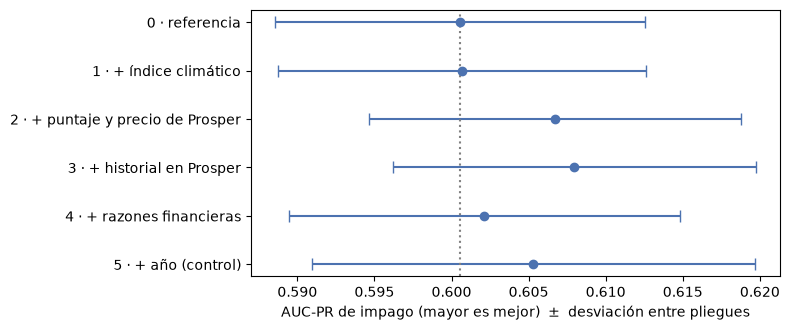

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.errorbar(ideas_table["AUC-PR"], range(len(ideas_table)), xerr=ideas_table["± entre pliegues"],
            fmt="o", color="#4c72b0", capsize=4)
ax.set_yticks(range(len(ideas_table))); ax.set_yticklabels(ideas_table.index)
ax.invert_yaxis(); ax.axvline(ideas_table.loc[REF, "AUC-PR"], color="grey", linestyle=":")
ax.set_xlabel("AUC-PR de impago (mayor es mejor)  ±  desviación entre pliegues")
plt.tight_layout(); plt.show()

## 6. Aplicar la regla tal como se escribió

In [8]:
IDEA_FLAGS = {
    "1 · + índice climático": "use_climate",
    "2 · + puntaje y precio de Prosper": "use_prosper_scores",
    "3 · + historial en Prosper": "use_prosper_history",
    "4 · + razones financieras": "use_ratios",
}  # la idea 5 (año) no es candidata: es un artefacto de la muestra (regla c)

kept_by_rule = [name for name in IDEA_FLAGS if ideas_table.loc[name, "mejora / ruido"] > 1]
print("Ideas que cumplen la regla escrita (mejora / ruido > 1):", kept_by_rule or "ninguna")

Ideas que cumplen la regla escrita (mejora / ruido > 1): ninguna


### Diagnóstico: ¿el ruido de la regla es el ruido correcto?

La desviación de la variante entre pliegues mezcla dos cosas: lo que cambia la idea y **lo difícil que es cada
pliegue**, que afecta igual a todas las variantes (los pliegues tienen los mismos préstamos). Por eso se miran
tres señales más, que la guía del curso pide revisar: los **pliegues ganados**, la **segunda métrica** (log loss) y el
**ruido de a pares**.

Además hay un riesgo propio de este dataset: los vacíos del puntaje de Prosper coinciden **100 %** con los préstamos de
antes de julio de 2009 (según el diccionario de datos, el puntaje existe desde esa fecha). Si la idea 2 mejorara solo por eso, estaría aprendiendo la época (lo mismo que la idea 5), no el
riesgo. Para separarlo, se mide cada idea **solo en los préstamos desde julio de 2009**, donde el 99,5 % tiene puntaje.

In [9]:
since_2009 = (train["LoanOriginationDate"] >= PROSPER_RATING_START).to_numpy()
print(f"préstamos desde julio de 2009 en entrenamiento: {since_2009.sum():,} ({since_2009.mean():.1%})")
era_table = comparison_table(oof, REF, mask=since_2009)[["AUC-PR", "mejora AUC-PR", "pliegues ganados", "mejora / ruido de a pares"]]
pd.concat({"todos los préstamos": ideas_table[["AUC-PR", "mejora AUC-PR", "pliegues ganados", "mejora / ruido de a pares",
                                              "mejora log loss / ruido"]],
           "solo desde julio de 2009": era_table}, axis=1).round(4)

préstamos desde julio de 2009 en entrenamiento: 20,792 (52.5%)


todos los préstamos                \
                                               AUC-PR mejora AUC-PR   
0 · referencia                                 0.6005        0.0000   
1 · + índice climático                         0.6007        0.0001   
2 · + puntaje y precio de Prosper              0.6067        0.0061   
3 · + historial en Prosper                     0.6080        0.0074   
4 · + razones financieras                      0.6021        0.0016   
5 · + año (control)                            0.6053        0.0048   

                                                                              \
                                  pliegues ganados mejora / ruido de a pares   
0 · referencia                                 NaN                    0.0000   
1 · + índice climático                         3.0                    0.0503   
2 · + puntaje y precio de Prosper              5.0                    2.8210   
3 · + historial en Prosper                     5.0                    4.4667   
4 · + razones financieras                      4.0                    0.7134   
5 · + año (control)                            5.0                    1.2320   

                                                           \
                                  mejora log loss / ruido   
0 · referencia                                     0.0000   
1 · + índice climático                             0.0644   
2 · + puntaje y precio de Prosper                  1.1107   
3 · + historial en Prosper                         1.2965   
4 · + razones financieras                          0.1791   
5 · + año (control)                                0.7347   

                                  solo desde julio de 2009                \
                                                    AUC-PR mejora AUC-PR   
0 · referencia                                      0.4644        0.0000   
1 · + índice climático                              0.4617       -0.0026   
2 · + puntaje y precio de Prosper                   0.4760        0.0117   
3 · + historial en Prosper                          0.4815        0.0171   
4 · + razones financieras                           0.4654        0.0010   
5 · + año (control)                                 0.4759        0.0115   

                                                                              
                                  pliegues ganados mejora / ruido de a pares  
0 · referencia                                 NaN                    0.0000  
1 · + índice climático                         2.0                   -0.3965  
2 · + puntaje y precio de Prosper              5.0                    2.9566  
3 · + historial en Prosper                     5.0                    3.9249  
4 · + razones financieras                      4.0                    0.1703  
5 · + año (control)                            5.0                    4.2848

### Excepción a la regla, justificada por escrito

La guía permite excepciones si se justifican por escrito. Se propone **una**: conservar las ideas 2 y 3, porque cumplen
las cuatro condiciones siguientes. El código las verifica, no se leen a ojo.

1. Ganan en los **5 de 5** pliegues.
2. Su mejora de **log loss / ruido es mayor que 1**.
3. Su **mejora / ruido de a pares es mayor que 2**.
4. La mejora **se mantiene en los préstamos desde julio de 2009**, en los 5 pliegues, así que no es la época disfrazada.

Las ideas que no cumplen las cuatro se descartan. **Esta excepción se decidió después de ver los datos y el grupo
debe confirmarla** (queda anotada así en `reports/04_features.md`).

In [10]:
def passes_exception(name):
    return bool(
        ideas_table.loc[name, "pliegues ganados"] == 5
        and ideas_table.loc[name, "mejora log loss / ruido"] > 1
        and ideas_table.loc[name, "mejora / ruido de a pares"] > 2
        and era_table.loc[name, "mejora AUC-PR"] > 0 and era_table.loc[name, "pliegues ganados"] == 5
    )

kept = [name for name in IDEA_FLAGS if name in kept_by_rule or passes_exception(name)]
print("Ideas conservadas:", kept or "ninguna")
final_flags = {IDEA_FLAGS[name]: True for name in kept if IDEA_FLAGS[name] != "use_climate"}
print("Conjunto final (sin clima):", final_flags or "solo la referencia")

Ideas conservadas: ['2 · + puntaje y precio de Prosper', '3 · + historial en Prosper']
Conjunto final (sin clima): {'use_prosper_scores': True, 'use_prosper_history': True}


## 7. La hipótesis climática sobre el conjunto final

La pregunta del caso es si el clima agrega información **más allá del perfil financiero**. Se mide sobre el conjunto
final, con y sin el índice, con los mismos pliegues. También se mide en los préstamos desde julio de 2009.

In [11]:
oof["final sin índice climático"] = run(final_flags)
oof["final con índice climático"] = run(dict(final_flags, use_climate=True))

final_names = ["final sin índice climático", "final con índice climático"]
climate_table = comparison_table({k: oof[k] for k in final_names}, final_names[0])
climate_era = comparison_table({k: oof[k] for k in final_names}, final_names[0], mask=since_2009)
display(climate_table.round(4))
climate_era[["AUC-PR", "mejora AUC-PR", "pliegues ganados", "mejora / ruido de a pares"]].round(4)

,AUC-PR,± entre pliegues,mejora AUC-PR,mejora / ruido,pliegues ganados,mejora / ruido de a pares,log loss,mejora log loss / ruido,Brier,ROC-AUC,costo 4 a 1,recall impago
final sin índice climático,0.6104,0.0117,0.0000,0.0000,NaN,0.0000,0.5103,0.0000,0.1703,0.7747,0.5176,0.8693
final con índice climático,0.6116,0.0118,0.0012,0.1004,4.0,0.6911,0.5094,0.2587,0.1700,0.7759,0.5163,0.8691


,AUC-PR,mejora AUC-PR,pliegues ganados,mejora / ruido de a pares
final sin índice climático,0.4855,0.0000,NaN,0.0000
final con índice climático,0.4892,0.0038,4.0,1.1241


## 8. Guardar la tabla de ideas

In [12]:
final_vs_ref = comparison_table({REF: oof[REF], final_names[0]: oof[final_names[0]]}, REF).loc[[final_names[0]]]
table = pd.concat([
    ideas_table,
    final_vs_ref.rename(index={final_names[0]: "final (vs referencia)"}),
    climate_table.loc[[final_names[1]]].rename(index={final_names[1]: "final + índice climático (vs final)"}),
])
table.to_csv(REPORTS_DIR / "04_features_tabla.csv")
numeric_final, categorical_final = feature_columns(**final_flags)
print(f"Conjunto final: {len(numeric_final)} numéricas y {len(categorical_final)} categóricas -> {final_flags}")
table.round(4)

Conjunto final: 41 numéricas y 7 categóricas -> {'use_prosper_scores': True, 'use_prosper_history': True}


,AUC-PR,± entre pliegues,mejora AUC-PR,mejora / ruido,pliegues ganados,mejora / ruido de a pares,log loss,mejora log loss / ruido,Brier,ROC-AUC,costo 4 a 1,recall impago
0 · referencia,0.6005,0.0120,0.0000,0.0000,NaN,0.0000,0.5168,0.0000,0.1728,0.7658,0.5312,0.8692
1 · + índice climático,0.6007,0.0119,0.0001,0.0100,3.0,0.0503,0.5165,0.0644,0.1728,0.7661,0.5262,0.8732
2 · + puntaje y precio de Prosper,0.6067,0.0121,0.0061,0.5087,5.0,2.8210,0.5131,1.1107,0.1713,0.7714,0.5184,0.8708
3 · + historial en Prosper,0.6080,0.0118,0.0074,0.6311,5.0,4.4667,0.5116,1.2965,0.1708,0.7725,0.5186,0.8750
4 · + razones financieras,0.6021,0.0127,0.0016,0.1243,4.0,0.7134,0.5160,0.1791,0.1725,0.7669,0.5270,0.8719
5 · + año (control),0.6053,0.0144,0.0048,0.3311,5.0,1.2320,0.5128,0.7347,0.1714,0.7713,0.5163,0.8723
final (vs referencia),0.6104,0.0117,0.0098,0.8392,5.0,4.8072,0.5103,1.7804,0.1703,0.7747,0.5176,0.8693
final + índice climático (vs final),0.6116,0.0118,0.0012,0.1004,4.0,0.6911,0.5094,0.2587,0.1700,0.7759,0.5163,0.8691


## 9. Lectura y decisiones

**Con la regla escrita, ninguna idea entra.** Ninguna supera mejora / ruido = 1 en AUC-PR (la mayor es la del
historial, 0,63). La desviación entre pliegues (≈ 0,012) es más grande que cualquier mejora, porque mide sobre todo lo
difícil que es cada pliegue.

**El diagnóstico separa dos grupos:**

| Idea | Mejora AUC-PR | Pliegues ganados | Log loss / ruido | De a pares | Desde julio 2009 | Decisión |
|---|---|---|---|---|---|---|
| 1 · Índice climático | +0,0001 | 3 de 5 | 0,06 | 0,05 | −0,0026 (2 de 5) | **Descartar** |
| 2 · Puntaje y precio de Prosper | +0,0061 | 5 de 5 | 1,11 | 2,82 | +0,0117 (5 de 5) | **Conservar** (excepción) |
| 3 · Historial en Prosper | +0,0074 | 5 de 5 | 1,30 | 4,47 | +0,0171 (5 de 5) | **Conservar** (excepción) |
| 4 · Razones financieras | +0,0016 | 4 de 5 | 0,18 | 0,71 | +0,0010 (4 de 5) | **Descartar** |
| 5 · Año (control) | +0,0048 | 5 de 5 | 0,73 | 1,23 | +0,0115 (5 de 5) | **No candidata**: artefacto de la muestra |

- **Ideas 2 y 3 sí aportan, y no es la época.** Mejoran en los 5 pliegues y en las dos métricas, y la mejora es
  incluso **mayor** en los préstamos desde julio de 2009, cuando Prosper empezó a asignar su puntaje (+0,012 y +0,017). Juntas llevan el AUC-PR de 0,6005 a 0,6104
  (de a pares 4,8) y el log loss de 0,517 a 0,510.
- **Las razones financieras no aportan:** LightGBM ya combina cuota, monto e ingreso por su cuenta.
- **El año sí "ayuda", y por eso es una advertencia.** La muestra solo tiene préstamos terminados, y los recientes que
  ya terminaron son sobre todo los que terminaron rápido. Un modelo en producción no puede aprovechar eso. La regla lo
  dejaba fuera desde antes de medir.

**La hipótesis climática no se sostiene con estos datos:**
- Contra la referencia: +0,0001 de AUC-PR (mejora / ruido 0,01).
- Sobre el conjunto final: +0,0012 (mejora / ruido 0,10; de a pares 0,69; 4 de 5 pliegues).
- Desde julio de 2009, la mejora sobre el conjunto final es +0,0038 (de a pares 1,12).

Es una tendencia pequeña dentro del ruido, que no cumple ni la regla ni la excepción. **Conclusión honesta:** con un
índice que da el mismo 50,0 a 41 de 51 estados, el clima **no agrega información medible** más allá del perfil
financiero. Si se usara, se penalizaría a prestatarios por su estado sin evidencia de que eso mejore la predicción.

**Conjunto final que pasa a la etapa 5:** referencia + puntaje y precio de Prosper + historial en Prosper (41
numéricas y 7 categóricas), **sin** índice climático. En la etapa 7 se reporta con y sin él, porque es la pregunta del
caso.

> **Excepción aprobada por el grupo el 31 oct:** se conservan el puntaje y el historial de Prosper aunque no pasaron
> la regla escrita antes de medir, por las cuatro condiciones de la sección 6.

**Siguiente:** `05_torneo.ipynb`, con estos mismos pliegues y el conjunto final.

## 10. Revisión de variables (31 oct): ¿hay que crear o eliminar alguna?

Una revisión del conjunto final, columna por columna, encontró cuatro tipos de problemas:

| Grupo | Columnas | Hallazgo |
|---|---|---|
| A · Redundantes | `TotalProsperPaymentsBilled`, `OpenCreditLines`, `TotalCreditLinespast7years`, `EstimatedReturn` | `Billed` = pagos a tiempo + atrasados en el 100 % de las filas; Spearman 0,95 con `CurrentCreditLines` y con `TotalTrades`; según el diccionario, `EstimatedReturn` = `EstimatedEffectiveYield` − `EstimatedLoss` |
| B · Casi constantes | `ProsperPaymentsOneMonthPlusLate`, `Recommendations`, `PublicRecordsLast12Months` | Valen 0 en el 99,6 %, el 92,7 % y el 90,4 % de los préstamos |
| C · Marcador de época | `CurrentlyInGroup` | 33 % de "sí" antes de julio de 2009 y 5 % después (Prosper retiró los grupos) |
| D · Recodificación de 2009 | `EmploymentStatus` | "Employed" solo existe desde julio de 2009 (63 %) y "Not available" solo antes (12,5 %). Se prueba agruparla: Employed/Full-time/Part-time → Employed; "Not available" → desconocido |
| E · Variables nuevas | `prosper_late_payment_rate`, `prosper_outstanding_share` | El historial en Prosper solo tiene conteos, con correlación 0,99 entre ellos (casi todos son 0). Se crean dos tasas de **comportamiento**: pagos atrasados / facturados y principal pendiente / prestado. Las dos se conocen al publicar la solicitud (diccionario) |

**Reglas escritas ANTES de medir** (se compara contra el conjunto final, en los mismos pliegues):

- **Eliminar o agrupar (A, B, C, D):** se acepta si el AUC-PR **no baja más que una vez el ruido de a pares**
  (mejora / ruido de a pares > −1), en todos los préstamos **y** desde julio de 2009. Menos columnas es menos que pedir
  en la app y menos riesgo de aprender la época.
- **Crear (E):** se acepta con la misma regla de la sección 1 o con la excepción aprobada de la sección 6.

In [13]:
from proyecto.features.engineering import (ERA_MARKER_COLUMNS, FINAL_FEATURES, NEAR_CONSTANT_COLUMNS,
                                         REDUNDANT_COLUMNS)

review_variants = {
    "A · − redundantes": dict(FINAL_FEATURES, exclude=REDUNDANT_COLUMNS),
    "B · − casi constantes": dict(FINAL_FEATURES, exclude=NEAR_CONSTANT_COLUMNS),
    "C · − CurrentlyInGroup (época)": dict(FINAL_FEATURES, exclude=ERA_MARKER_COLUMNS),
    "D · EmploymentStatus agrupado": dict(FINAL_FEATURES, group_employment=True),
    "E · + tasas de comportamiento en Prosper": dict(FINAL_FEATURES, use_history_rates=True),
}
review_oof = {"final": oof["final sin índice climático"]}   # mismas variables, mismo modelo, mismos pliegues
for name, flags in review_variants.items():
    review_oof[name] = run(flags)
    print(f"{name:42s} AUC-PR = {fold_metrics(y, review_oof[name], folds)['pr_auc'].mean():.4f}")

cols = ["AUC-PR", "mejora AUC-PR", "pliegues ganados", "mejora / ruido de a pares", "mejora log loss / ruido"]
review_table = pd.concat({
    "todos los préstamos": comparison_table(review_oof, "final")[cols],
    "desde julio de 2009": comparison_table(review_oof, "final", mask=since_2009)[cols[:4]],
}, axis=1)
review_table.round(4)

A · − redundantes                          AUC-PR = 0.6105


B · − casi constantes                      AUC-PR = 0.6098


C · − CurrentlyInGroup (época)             AUC-PR = 0.6113


D · EmploymentStatus agrupado              AUC-PR = 0.6096


E · + tasas de comportamiento en Prosper   AUC-PR = 0.6117


todos los préstamos                \
                                                      AUC-PR mejora AUC-PR   
final                                                 0.6104        0.0000   
A · − redundantes                                     0.6105        0.0001   
B · − casi constantes                                 0.6098       -0.0006   
C · − CurrentlyInGroup (época)                        0.6113        0.0009   
D · EmploymentStatus agrupado                         0.6096       -0.0008   
E · + tasas de comportamiento en Prosper              0.6117        0.0013   

                                                           \
                                         pliegues ganados   
final                                                 NaN   
A · − redundantes                                     3.0   
B · − casi constantes                                 1.0   
C · − CurrentlyInGroup (época)                        3.0   
D · EmploymentStatus agrupado                         2.0   
E · + tasas de comportamiento en Prosper              4.0   

                                                                    \
                                         mejora / ruido de a pares   
final                                                       0.0000   
A · − redundantes                                           0.1631   
B · − casi constantes                                      -0.6971   
C · − CurrentlyInGroup (época)                              0.5918   
D · EmploymentStatus agrupado                              -0.3237   
E · + tasas de comportamiento en Prosper                    0.6996   

                                                                  \
                                         mejora log loss / ruido   
final                                                     0.0000   
A · − redundantes                                         0.0861   
B · − casi constantes                                    -0.0397   
C · − CurrentlyInGroup (época)                            0.0927   
D · EmploymentStatus agrupado                             0.0045   
E · + tasas de comportamiento en Prosper                  0.2823   

                                         desde julio de 2009                \
                                                      AUC-PR mejora AUC-PR   
final                                                 0.4855        0.0000   
A · − redundantes                                     0.4877        0.0022   
B · − casi constantes                                 0.4856        0.0002   
C · − CurrentlyInGroup (época)                        0.4894        0.0040   
D · EmploymentStatus agrupado                         0.4873        0.0018   
E · + tasas de comportamiento en Prosper              0.4929        0.0074   

                                                           \
                                         pliegues ganados   
final                                                 NaN   
A · − redundantes                                     4.0   
B · − casi constantes                                 3.0   
C · − CurrentlyInGroup (época)                        3.0   
D · EmploymentStatus agrupado                         4.0   
E · + tasas de comportamiento en Prosper              5.0   

                                                                    
                                         mejora / ruido de a pares  
final                                                       0.0000  
A · − redundantes                                           0.7873  
B · − casi constantes                                       0.0795  
C · − CurrentlyInGroup (época)                              0.6885  
D · EmploymentStatus agrupado                               0.4581  
E · + tasas de comportamiento en Prosper                    1.7355

In [14]:
def accept_removal(name):
    return bool(review_table.loc[name, ("todos los préstamos", "mejora / ruido de a pares")] > -1
                and review_table.loc[name, ("desde julio de 2009", "mejora / ruido de a pares")] > -1)

def accept_creation(name):
    t, e = review_table.loc[name, "todos los préstamos"], review_table.loc[name, "desde julio de 2009"]
    by_rule = t["mejora AUC-PR"] / comparison_table(review_oof, "final").loc[name, "± entre pliegues"] > 1
    by_exception = (t["pliegues ganados"] == 5 and t["mejora log loss / ruido"] > 1 and t["mejora / ruido de a pares"] > 2
                    and e["mejora AUC-PR"] > 0 and e["pliegues ganados"] == 5)
    return bool(by_rule or by_exception)

decisions = {name: (accept_creation(name) if name.startswith("E") else accept_removal(name)) for name in review_variants}
for name, ok in decisions.items():
    print(f"{name:42s} -> {'se acepta' if ok else 'NO se acepta'}")

# Conjunto revisado: el final con todos los cambios aceptados, medido otra vez (los efectos pueden sumarse)
revised = dict(FINAL_FEATURES)
exclude = []
for name, ok in decisions.items():
    if ok:
        flags = review_variants[name]
        exclude += list(flags.get("exclude", []))
        revised.update({k: v for k, v in flags.items() if k != "exclude"})
if exclude:
    revised["exclude"] = exclude
review_oof["revisado (todos los cambios aceptados)"] = run(revised)
combined = pd.concat({
    "todos los préstamos": comparison_table({k: review_oof[k] for k in ["final", "revisado (todos los cambios aceptados)"]}, "final")[cols],
    "desde julio de 2009": comparison_table({k: review_oof[k] for k in ["final", "revisado (todos los cambios aceptados)"]}, "final",
                                            mask=since_2009)[cols[:4]],
}, axis=1)
num_rev, cat_rev = feature_columns(**revised)
print("conjunto revisado:", revised)
print(f"columnas: {len(num_rev)} numéricas y {len(cat_rev)} categóricas (antes 41 y 7)")
review_table.to_csv(REPORTS_DIR / "04_revision_variables.csv")
combined.round(4)

A · − redundantes                          -> se acepta
B · − casi constantes                      -> se acepta
C · − CurrentlyInGroup (época)             -> se acepta
D · EmploymentStatus agrupado              -> se acepta
E · + tasas de comportamiento en Prosper   -> NO se acepta


conjunto revisado: {'use_prosper_scores': True, 'use_prosper_history': True, 'group_employment': True, 'exclude': ['TotalProsperPaymentsBilled', 'OpenCreditLines', 'TotalCreditLinespast7years', 'EstimatedReturn', 'ProsperPaymentsOneMonthPlusLate', 'Recommendations', 'PublicRecordsLast12Months', 'CurrentlyInGroup']}
columnas: 34 numéricas y 6 categóricas (antes 41 y 7)


todos los préstamos                \
                                                    AUC-PR mejora AUC-PR   
final                                               0.6104        0.0000   
revisado (todos los cambios aceptados)              0.6107        0.0003   

                                                         \
                                       pliegues ganados   
final                                               NaN   
revisado (todos los cambios aceptados)              3.0   

                                                                  \
                                       mejora / ruido de a pares   
final                                                     0.0000   
revisado (todos los cambios aceptados)                    0.1473   

                                                                \
                                       mejora log loss / ruido   
final                                                   0.0000   
revisado (todos los cambios aceptados)                  0.1008   

                                       desde julio de 2009                \
                                                    AUC-PR mejora AUC-PR   
final                                               0.4855        0.0000   
revisado (todos los cambios aceptados)              0.4851       -0.0004   

                                                         \
                                       pliegues ganados   
final                                               NaN   
revisado (todos los cambios aceptados)              2.0   

                                                                  
                                       mejora / ruido de a pares  
final                                                     0.0000  
revisado (todos los cambios aceptados)                   -0.0751

### Lectura de la revisión

| Cambio | Mejora AUC-PR | De a pares | Desde julio 2009 (de a pares) | Decisión |
|---|---|---|---|---|
| A · Quitar redundantes (4 columnas) | +0,0001 | 0,16 | +0,0022 (0,79) | **Se acepta** |
| B · Quitar casi constantes (3) | −0,0006 | −0,70 | +0,0002 (0,08) | **Se acepta**: baja menos que el ruido |
| C · Quitar `CurrentlyInGroup` | +0,0009 | 0,59 | +0,0040 (0,69) | **Se acepta** |
| D · Agrupar `EmploymentStatus` | −0,0008 | −0,32 | +0,0018 (0,46) | **Se acepta** |
| E · Crear tasas de comportamiento en Prosper | +0,0013 | 0,70 | +0,0074 (1,74; 5 de 5) | **No se acepta** |

- **El conjunto revisado rinde igual con menos columnas.** Juntos, A–D dan AUC-PR 0,6107 (frente a 0,6104; de a
  pares 0,15) y −0,0004 desde julio de 2009 (de a pares −0,08). El modelo pasa de **41 a 34 numéricas y de 7 a 6
  categóricas**: son 8 columnas menos que pedir en la app.
- **Además se gana robustez.** `CurrentlyInGroup` y la codificación vieja de `EmploymentStatus` marcaban la época:
  fuera de la muestra (préstamos nuevos) esas señales no existen.
- **Las tasas de comportamiento (E) quedan como idea prometedora, no aprobada.** Desde julio de 2009 mejoran en los 5
  pliegues (+0,0074), pero en todos los préstamos la mejora está dentro del ruido y el log loss casi no cambia (0,28).
  No cumplen la regla ni la excepción. Se pueden revisar en la etapa 7 si el modelo se valida solo con préstamos
  recientes.

**Decisión:** `FINAL_FEATURES` pasa a ser el conjunto revisado (en `src/proyecto/features/engineering.py`). Los
notebooks 05 y 06 se vuelven a ejecutar con él.